In [2]:
#importing pandas library
import pandas as pd

In [6]:
#loading data
titanic = pd.read_csv(r"C:\Users\pooja\Downloads\titanic.csv")

In [7]:
# View first five rows of the dataset
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [8]:
titanic.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

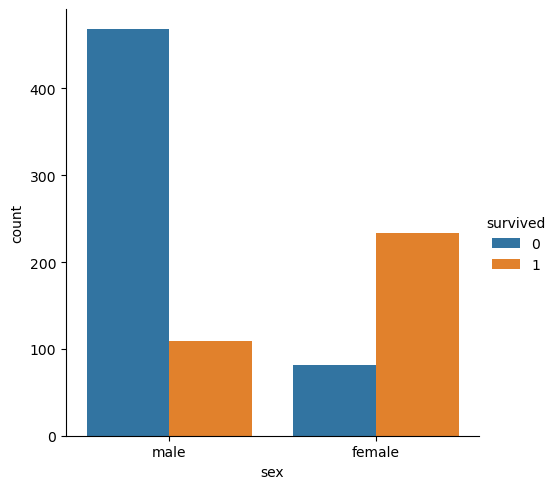

In [15]:
# Countplot
sns.catplot(x ="sex", hue ="survived",kind ="count", data = titanic)

In [21]:
# Group the dataset by Pclass and Survived and then unstack them
group = titanic.groupby(['pclass', 'survived'])
pclass_survived = group.size().unstack()

<Axes: xlabel='survived', ylabel='pclass'>

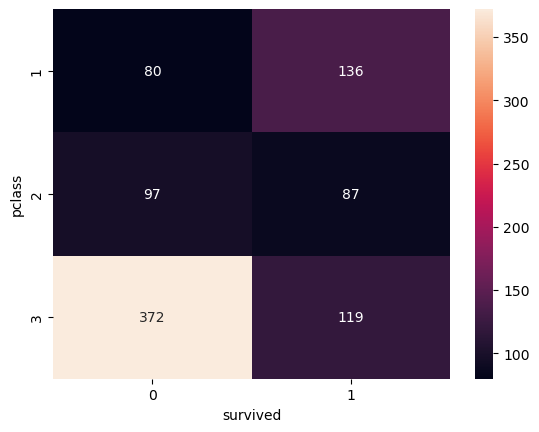

In [22]:
# Heatmap - Color encoded 2D representation of data.
sns.heatmap(pclass_survived, annot = True, fmt ="d")

<Axes: xlabel='sex', ylabel='age'>

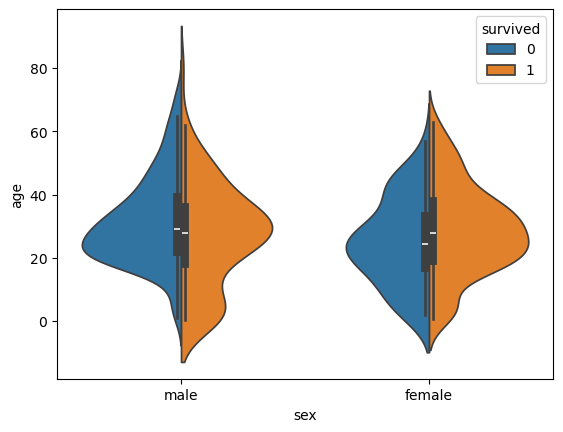

In [23]:
# Violinplot Displays distribution of data 
# across all levels of a category.
sns.violinplot(x ="sex", y ="age", hue ="survived", 
data = titanic, split = True)

<Axes: xlabel='Family_Size', ylabel='survived'>

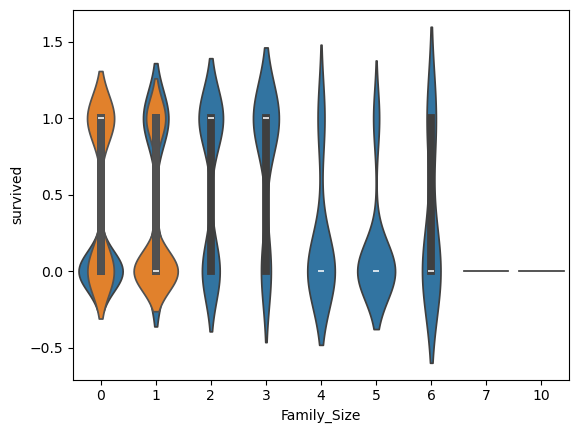

In [39]:
# Adding a column Family_Size
titanic['Family_Size'] = 0
titanic['Family_Size'] = titanic['parch']+titanic['sibsp']

# Adding a column Alone
titanic['alone'] = 0
titanic.loc[titanic.Family_Size == 0, 'alone'] = 1

# Factorplot for Family_Size
sns.violinplot(x ='Family_Size', y ='survived', data = titanic)

# Factorplot for Alone
sns.violinplot(x ='alone', y ='survived', data = titanic)

<Axes: xlabel='fare_range', ylabel='survived'>

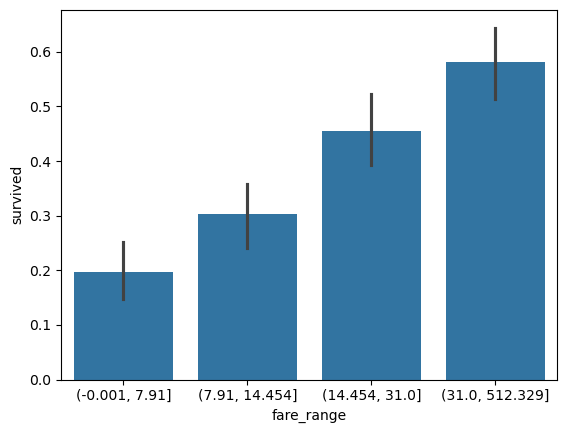

In [40]:
# Divide Fare into 4 bins
titanic['fare_range'] = pd.qcut(titanic['fare'], 4)

# Barplot - Shows approximate values based 
# on the height of bars.
sns.barplot(x ='fare_range', y ='survived', data = titanic)

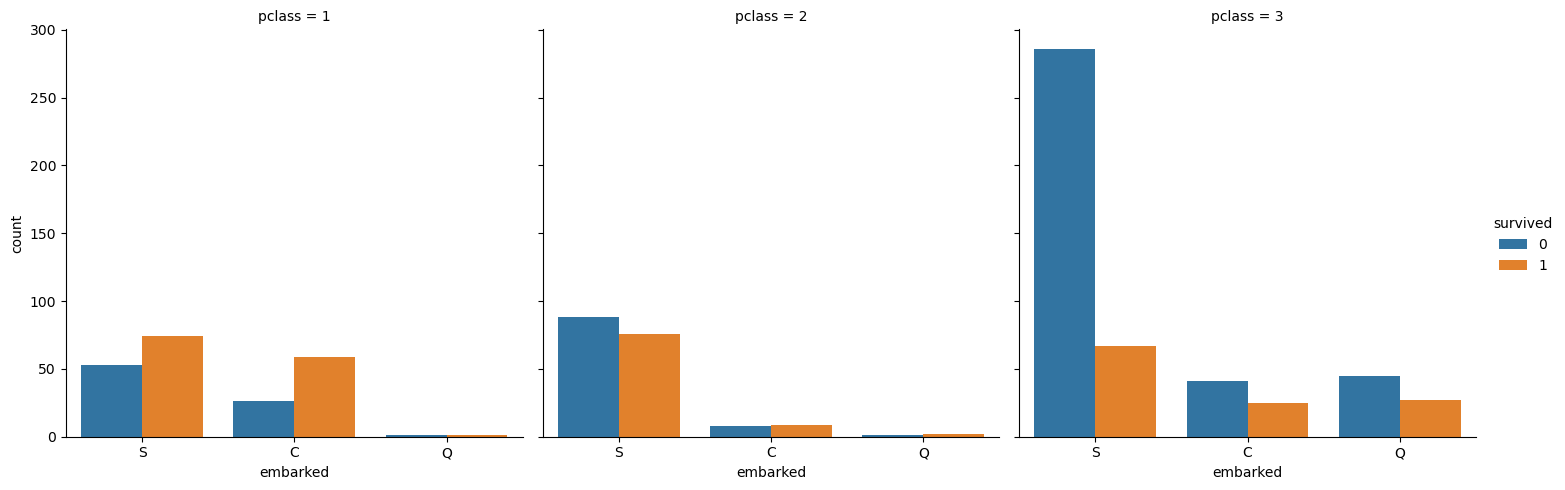

In [41]:
# Countplot
sns.catplot(x ='embarked', hue ='survived',kind ='count', col ='pclass', data = titanic)